# Tres formas de curva alrededor de un tamaño medio: Rosin-Rammler, Swebrec y la composición de zona de trituración, y el tope en el bloque in situ

**Nivel 2: El método en la práctica** · Requiere: 03-size-distribution/01-from-a-mean-size-to-a-curve · Tiempo de lectura: unos 25 minutos

## Objetivos

La curva de Rosin-Rammler tiene dos debilidades conocidas: subestima los finos y no tiene un límite superior para el tamaño de fragmento. El motor incluye dos formas de curva más alrededor del mismo tamaño medio, y un tope estructural. Este cuaderno las compara en un tiro y dice exactamente qué agrega cada una.

Al terminar habrá:

- construido las curvas Swebrec y de zona de trituración para el tiro `En1` de Enusa y comparado su P20, P50 y P80 con los de Rosin-Rammler;
- verificado las tres contra las curvas que versionó la ejecución offline;
- variado el parámetro de ondulación de Swebrec, y aplicado el tope en el tamaño del bloque in situ para ver qué cambia.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

Esta celda aún no importa nada del cuaderno: lee las versiones instaladas desde los metadatos de los paquetes y las imprime, de modo que la salida registra qué motor produjo cada número que sigue.

In [1]:
# Imprima la versión instalada de cada paquete que usa este cuaderno
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el cuaderno |
|---|---|---|---|
| El corpus y los patrones reconstruidos | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| La función Swebrec | Ouchterlony 2005, https://doi.org/10.1179/037178405x44539, tal como la imprimen Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (Ecs. 10 y 11) | la ecuación se reproduce con cita | `bf.swebrec` |
| El contraejemplo de Swebrec | Babaeian et al. 2019, https://doi.org/10.1016/j.jrmge.2018.11.006 | solo citado | ninguno (una afirmación en el docstring del propio motor) |
| Las distribuciones versionadas del caso Enusa | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/real-enusa/case.json`, campo `distributions` |

## Método

**Swebrec** (Ouchterlony 2005, tal como lo imprimen Amoako et al. 2022, Ecs. 10 y 11):

```
P(x) = 1 / (1 + f(x)),   f(x) = [ ln(x_max / x) / ln(x_max / x50) ]^b
```

Tres parámetros en vez de dos. El límite superior `x_max` fija la cola gruesa (el motor toma el mayor entre bordo y espaciamiento) y la ondulación `b` moldea los finos. Amoako et al. declaran que la función "es capaz de predecir mejor los finos". El motor guarda un contraejemplo a su lado: Babaeian et al. 2019 encontraron Rosin-Rammler más cerca del análisis de imágenes en una mina de bauxita, así que Swebrec no se presenta como estrictamente mejor.

**Composición de zona de trituración.** Dos modos de falla actúan a la vez: la fractura por tracción da los fragmentos gruesos y la fractura por compresión y corte alrededor del pozo da los finos. El motor mezcla una rama gruesa de Rosin-Rammler con una segunda rama más fina, por masa. La estructura proviene de Amoako et al. 2022, pero las constantes de las ramas (tamaño de cruce, uniformidad de finos, fracción de finos) **no están publicadas** en ninguna fuente disponible para este trabajo, así que son valores de partida plausibles y cada resultado lo dice.

**Tope en el bloque in situ.** Un tiro rompe bloques y no los funde, así que la masa que una curva coloca sobre el tamaño de bloque in situ `XB` se lee como bloques sin romper en `XB`: `P_tope(x) = P(x)` bajo `XB` y 1 desde `XB`. Es una decisión de modelado declarada del motor, no una relación publicada.

### Paso 1: tres curvas, un tiro

Los tres brazos `KuzRam`, `Swebrec` y `CrushZone` comparten el tamaño medio clásico y difieren solo en la curva, así que a cada uno se le pide su `distribution` del mismo tiro `En1`. La celda imprime los percentiles, la nota del motor sobre las constantes de la zona de trituración, y dibuja las tres curvas.

curva          P20 (m)   P50 (m)   P80 (m)
kuz-ram         0.0732    0.4399    1.6679
swebrec         0.0347    0.4398    1.5666
crush-zone      0.0507    0.3895    1.5845
las constantes de zona de trituración están publicadas: False
parámetros de zona de trituración: CrushZoneParameters(crossover_m=0.01, fines_uniformity=0.8, fines_fraction=0.05, source='structure from Amoako, Jha and Zhong 2022 section 3 describing Kanchibotla et al. 1999 and Djordjevic 1999; the branch constants are NOT published in any source held for this work and are supplied by the caller')


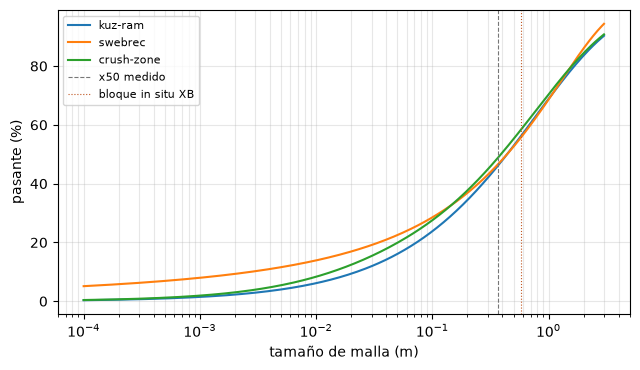

In [2]:
# Importaciones, y luego las tres distribuciones del mismo tiro y sus percentiles
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
blast = next(b for b in train if b.blast_id == "En1")
arms = {"kuz-ram": bf.KuzRam(), "swebrec": bf.Swebrec(), "crush-zone": bf.CrushZone()}
curves = {name: arm.distribution(blast) for name, arm in arms.items()}
print(f"{'curva':<12}{'P20 (m)':>10}{'P50 (m)':>10}{'P80 (m)':>10}")
for name, curve in curves.items():
    print(f"{name:<12}{curve.percentile_m(0.2):>10.4f}{curve.percentile_m(0.5):>10.4f}{curve.percentile_m(0.8):>10.4f}")
print("las constantes de zona de trituración están publicadas:", curves["crush-zone"].detail["constants_are_published"])
print("parámetros de zona de trituración:", curves["crush-zone"].detail["parameters"])

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for name, curve in curves.items():
    ax.plot(curve.sizes_m, [100 * p for p in curve.passing], label=name)
ax.axvline(blast.x50_m, color="#777", lw=0.8, ls="--", label="x50 medido")
ax.axvline(blast.XB_m, color="#c05621", lw=0.8, ls=":", label="bloque in situ XB")
ax.set_xscale("log")
ax.set_xlabel("tamaño de malla (m)")
ax.set_ylabel("pasante (%)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()

### Paso 2: verificar las tres contra las curvas versionadas

La ejecución offline escribió en `case.json` las tres curvas del tiro representativo del caso Enusa. La celda compara cada punto de cada curva e imprime la mayor diferencia.

In [3]:
# Mayor diferencia entre cada curva reconstruida y la versionada
artifact = json.loads((DERIVED / "real-enusa" / "case.json").read_text(encoding="utf-8"))
print("tiro representativo versionado:", artifact["representative_blast_id"])
for name, curve in curves.items():
    committed = artifact["distributions"][name]
    gap = max(abs(a - b) for a, b in zip(curve.passing, committed["passing"]))
    print(f"{name:<12} mayor diferencia = {gap:.1e}   constants_published versionado = {committed['constants_published']}")

tiro representativo versionado: En1
kuz-ram      mayor diferencia = 5.0e-07   constants_published versionado = True
swebrec      mayor diferencia = 5.0e-07   constants_published versionado = True
crush-zone   mayor diferencia = 5.0e-07   constants_published versionado = False


### Paso 3: el parámetro de ondulación

La ondulación `b` de Swebrec no tiene un ajuste publicado en este corpus, así que el valor por defecto del motor es un valor de partida. La celda lo escala por 0,5, 1 y 1,5 e informa el efecto sobre los finos (P20) y el extremo grueso (P80), con el tamaño medio sin cambio.

In [4]:
# Escalar la ondulación por defecto y leer los finos y el extremo grueso
default = bf.Swebrec().undulation
print(f"{'ondulación b':>16}{'P20 (m)':>10}{'P50 (m)':>10}{'P80 (m)':>10}")
for factor in (0.5, 1.0, 1.5):
    curve = bf.Swebrec(undulation=default * factor).distribution(blast)
    print(f"{default * factor:>16.2f}{curve.percentile_m(0.2):>10.4f}{curve.percentile_m(0.5):>10.4f}{curve.percentile_m(0.8):>10.4f}")

    ondulación b   P20 (m)   P50 (m)   P80 (m)
            1.00    0.0002    0.4398    2.9561
            2.00    0.0347    0.4398    1.5666
            3.00    0.0989    0.4398    1.1262


### Paso 4: el tope en el bloque in situ

Para `En1` el P80 de Rosin-Rammler es mayor que el bloque in situ `XB`. `cap_at_in_situ_block` recorta la curva a 1 desde `XB`, lo que baja los percentiles superiores pero deja el tamaño medio intacto salvo que supere el bloque. La celda lo aplica a las tres curvas, y luego al tiro `Rc1` del corpus, cuyo tamaño medio clásico supera su bloque.

In [5]:
# Topar cada curva en el tamaño de bloque in situ y comparar los percentiles superiores y el sobretamaño
print("bloque in situ de", blast.blast_id, "=", blast.XB_m, "m")
print(f"{'curva':<12}{'P80':>9}{'P80 topado':>14}{'masa sobre XB, sin tope':>34}")
for name, curve in curves.items():
    capped = bf.cap_at_in_situ_block(curve, blast.XB_m)
    print(f"{name:<12}{curve.percentile_m(0.8):>9.3f}{capped.percentile_m(0.8):>14.3f}{1 - curve.passing_at(blast.XB_m):>34.1%}")

rc1 = next(b for b in train if b.blast_id == "Rc1")
capped_rc1 = bf.cap_at_in_situ_block(arms["kuz-ram"].distribution(rc1), rc1.XB_m)
print(f"{rc1.blast_id}: tamaño medio clásico {capped_rc1.detail['uncapped_x50_m']:.3f} m, bloque {rc1.XB_m} m, media topada {capped_rc1.x50_m:.3f} m, el tope actúa: {capped_rc1.detail['cap_binds']}")

bloque in situ de En1 = 0.58 m
curva             P80    P80 topado           masa sobre XB, sin tope
kuz-ram         1.668         0.575                             43.8%
swebrec         1.567         0.575                             44.3%
crush-zone      1.585         0.575                             41.6%
Rc1: tamaño medio clásico 0.720 m, bloque 0.68 m, media topada 0.680 m, el tope actúa: True


## Resultados

**Las tres curvas comparten un tamaño medio y difieren en las colas.** Swebrec pone más masa en los finos que Rosin-Rammler (un P20 menor) y, con su límite superior, un extremo superior más fino (un P80 menor). La mezcla de zona de trituración mueve la propia mediana: agrega una fracción declarada de finos, de modo que su P50 queda bajo el tamaño medio clásico. Las tres coinciden con las curvas versionadas hasta el redondeo del archivo.

**La ondulación mueve ambos extremos.** Escalar `b` por 0,5 y 1,5 cambia el P20 en órdenes de magnitud y el P80 de unos tres metros a cerca de uno, con el tamaño medio sin cambio, por lo que el motor la trata como una entrada que se fija, no como algo que se ajusta en silencio.

**El tope cambia el extremo superior y nada más.** Para `En1` cada curva sin tope coloca cerca de cuarenta por ciento de su masa sobre el bloque in situ, lo que es físicamente imposible; el tope baja los percentiles superiores hasta el bloque. Para `Rc1` el propio tamaño medio clásico supera el bloque, y el tope actúa sobre la media.

**Qué no muestra esto.** Ninguna de estas curvas se comparó con una distribución de tamaños medida, y las constantes de zona de trituración no son valores publicados. Las diferencias de la tabla son diferencias entre formas de modelo, no diferencias de exactitud. Por eso este tema no tiene un cuaderno de estado del arte: con solo el tamaño medio medido, no hay contra qué ordenar las formas.

## Resumen

- Tres formas de curva comparten un tamaño medio; difieren en los finos (Swebrec, zona de trituración) y en el extremo grueso (el límite superior de Swebrec).
- Las constantes de zona de trituración no son valores publicados, y no existe una distribución de tamaños medida para ordenar las formas.
- El tope en el bloque in situ elimina sobretamaño físicamente imposible y, donde la media supera el bloque, baja la media.
- Siguiente: el tema 04 pasa de lo que predice un modelo a cómo se juzga una predicción.

## Referencias

- Ouchterlony 2005, https://doi.org/10.1179/037178405x44539 (la función Swebrec)
- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (Ecs. 5, 10 y 11 y la descripción del mecanismo de zona de trituración)
- Babaeian et al. 2019, https://doi.org/10.1016/j.jrmge.2018.11.006 (el contraejemplo de bauxita para Swebrec)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/